# SIMURGENCIAS · Entrega 1
Datos sintéticos, modelo académico.
Instalar las dependencias de backend/requirements-lab.txt. La celda de importaciones localiza backend automáticamente al abrir este cuaderno desde el proyecto.
En Colab: clonar el repositorio e instalar las dependencias antes de ejecutar.

## 1. Importaciones
Usamos el mismo motor del backend; no mantenemos una segunda implementación.

In [14]:
import sys
print(sys.executable)

c:\Users\PC\Desktop\SIMURGENCIAS\backend\.venv\Scripts\python.exe


In [2]:
from pathlib import Path
import sys

backend_candidates = (Path.cwd() / "backend", Path.cwd().parent / "backend", Path.cwd())
backend_path = next((path.resolve() for path in backend_candidates if (path / "app").is_dir()), None)
if backend_path is None:
    raise RuntimeError("No se encontró backend/app. Abre el notebook del proyecto o ejecuta desde backend/.")
sys.path.insert(0, str(backend_path))

from app.simulation.domain import SimulationConfig
from app.simulation.engine import EmergencyDepartment
from app.simulation.theory import mmc
import matplotlib.pyplot as plt


## 2. Configuración
Todas las tasas son sintéticas. El reloj empieza a las 00:00 y mide minutos.

In [3]:
config = SimulationConfig(doctors=2, triage_staff=1,
    duration_minutes=1440, seed=42,
    arrival_rates_per_hour=(2, 5, 9, 6))


## 3. Entidades
Patient conserva marcas de tiempo individuales para reconstruir cada recorrido.

In [4]:
from app.simulation.domain import Patient, Doctor, TriageStation
# Las entidades se crean dentro del motor, al ocurrir la llegada.


## 4. Recursos
SimPy limita de verdad el acceso a triage, médicos y camas.

In [5]:
department = EmergencyDepartment(config)
print(department.doctors.resource.capacity)
print(department.triage.resource.capacity)
print(department.beds.capacity)


2
1
4


## 5. Proceso del paciente
El generador solicita recursos, espera, consume tiempo y libera capacidad.

In [6]:
import inspect
print(inspect.getsource(EmergencyDepartment.patient_process))


    def patient_process(self, p):
        self.change(active=1, triage_queue=1)
        with self.triage.resource.request() as request:
            yield request
            p.triage_start = float(self.env.now)
            p.state = "triage"
            self.change(triage_queue=-1, triage_busy=1)
            yield self.env.timeout(p.triage_service)
            p.triage_end = float(self.env.now)
            self.change(triage_busy=-1, doctor_queue=1)
        p.state = "doctor_queue"
        with self.doctors.resource.request(priority=self.priority.priority(p.triage_level)) as request:
            # Count actual pending requests; an immediate grant never enters the queue.
            self.max_doctor_queue = max(self.max_doctor_queue, len(self.doctors.resource.queue))
            yield request
            p.consultation_start = float(self.env.now)
            p.state = "consultation"
            self.change(doctor_queue=-1, doctors_busy=1)
            yield self.env.timeout(p.consultation

## 6. Llegadas
La inversión del riesgo acumulado respeta cada cambio de franja, incluso tasas cero.

In [7]:
from app.simulation.strategies import TimeVaryingArrivalStrategy
print(inspect.getsource(TimeVaryingArrivalStrategy))


class TimeVaryingArrivalStrategy(ArrivalStrategy):
    """Exact integrated-hazard inversion for a piecewise constant NHPP.

    Remaining exponential hazard crosses period boundaries, including zero-rate
    periods. No draw from the old rate is allowed to skip a rate change.
    """
    def __init__(self, rates_per_hour):
        self.rates = tuple(rate / 60 for rate in rates_per_hour)
        if not any(self.rates):
            raise ValueError("Se requiere alguna tasa positiva")

    def next_delay(self, now, rng):
        hazard = rng.expovariate(1)
        cursor = now
        while True:
            period = int(cursor // 360)
            boundary = (period + 1) * 360
            rate = self.rates[period % 4]
            available = (boundary - cursor) * rate
            if rate > 0 and hazard < available:
                return cursor - now + hazard / rate
            hazard -= available
            cursor = boundary



## 7. Ejecución
Una instancia nueva por réplica: la semilla reproduce sus resultados.

In [8]:
result = department.run().model_dump()
assert result == EmergencyDepartment(config).run().model_dump()


## 8. Métricas
Las utilizaciones y longitudes promedio se integran por evento, sin depender del muestreo.

In [9]:
result["metrics"]


{'generated': 144,
 'treated': 130,
 'discharged': 130,
 'abandoned': 0,
 'active_at_end': 14,
 'mean_wait_minutes': 21.612886320761618,
 'mean_system_minutes': 64.40802407283844,
 'p50_wait_minutes': 10.127034095655574,
 'p95_wait_minutes': 97.09306297097127,
 'p99_wait_minutes': 147.17783024456725,
 'probability_wait': 0.8409090909090909,
 'max_queue_length': 14,
 'consultation_started': 132,
 'throughput_per_minute': 0.09027777777777778,
 'throughput_per_hour': 5.416666666666667,
 'mean_service_minutes': 17.957254238922147,
 'mean_triage_wait_minutes': 10.287615003749446,
 'mean_queue_length': 3.100747031327183,
 'mean_triage_queue_length': 1.0287615003749446,
 'mean_observation_queue_length': 0.0,
 'doctor_utilization': 0.8289230434093117,
 'triage_utilization': 0.5790730565207096,
 'bed_utilization': 0.1883364513208728,
 'mean_active': 7.119773480324952,
 'duration_minutes': 1440.0,
 'final_state': {'active': 14,
  'triage_queue': 0,
  'doctor_queue': 12,
  'observation_queue': 0,

## 9. Gráficas
La serie muestra pacientes esperando consulta. Los promedios incluyen todo el horizonte.

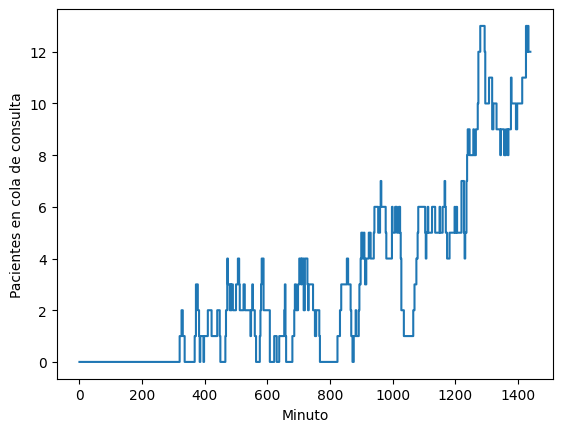

In [10]:
points = result["timeline"]
plt.step([p["minute"] for p in points],
         [p["doctor_queue"] for p in points], where="post")
plt.xlabel("Minuto"); plt.ylabel("Pacientes en cola de consulta")
plt.show()


## 10. M/M/c
Solo calculamos una referencia analítica para una cola aislada con Poisson estacionario, servicio exponencial y FIFO.

In [11]:
reference = mmc(arrival_per_hour=5, service_mean_minutes=18, servers=2)
reference


{'lambda_per_minute': 0.08333333333333333,
 'mu_per_minute': 0.05555555555555555,
 'c': 2,
 'rho': 0.75,
 'stable': True,
 'P0': 0.14285714285714285,
 'Pq': 0.6428571428571429,
 'P_wait': 0.6428571428571429,
 'Wq': 23.142857142857146,
 'W': 41.142857142857146,
 'Lq': 1.9285714285714288,
 'L': 3.428571428571429}

## 11. Ley de Little
El corte deja pacientes sin egreso; su tiempo acumulado explica el residuo.

In [12]:
little = result["little"]
print(little)
if little["difference"] is not None:
    assert abs(little["difference"] - little["censored_contribution"]) < 1e-8


{'L_observed': 7.119773480324952, 'lambda_observed_per_minute': 0.09027777777777778, 'W_observed_minutes': 64.40802407283844, 'lambda_W': 5.81461328435347, 'difference': 1.3051601959714816, 'censored_contribution': 1.305160195971484, 'queue': {'Lq_observed': 3.100747031327183, 'lambda_starts_per_minute': 0.09166666666666666, 'Wq_observed_minutes': 21.612886320761618, 'lambda_Wq': 1.9811812460698148, 'difference': 1.1195657852573684, 'censored_contribution': 1.1195657852573713}, 'explanation': 'λ usa egresos/horizonte y W solo egresados. L integra todos los activos. La diferencia es el tiempo acumulado de pacientes aún presentes al corte; no se drenan las colas.'}


## 12. Comparación
Una réplica para cada decisión de capacidad. No constituye una recomendación hospitalaria.

In [13]:
scenarios = [EmergencyDepartment(config.model_copy(update={"doctors": c})).run()
             for c in (1, 2, 3, 4)]
[(r.config.doctors, r.metrics["mean_wait_minutes"]) for r in scenarios]


[(1, 58.84095537711274),
 (2, 21.612886320761618),
 (3, 2.18865915275281),
 (4, 0.5090993953666619)]